# 06 · Advanced retrievers

Notebook 05 showed where the baseline struggles: questions that need facts from *several*
chunks (comparative, multi-hop) and questions that are really *filters* ("hotels in Asia with a
pool"). This notebook tries three classic fixes, each adding an LLM call somewhere in retrieval:

| Retriever | Idea | Extra LLM calls per question |
|---|---|---|
| **MultiQuery** | Ask the question several ways and merge the results | 1 (writes the variants) |
| **Contextual compression** | Retrieve, then keep only the relevant sentences | 1 per retrieved chunk |
| **SelfQuery** | Turn the question into a search query + a metadata filter | 1 (writes the query) |

> **Legacy API note.** In LangChain 1.x these three retrievers live in the `langchain_classic`
> package. They still work and are widely used, but new LangChain features land elsewhere
> (notebook 12 builds the same ideas as an agent). Learn the *ideas* here; the API may move.

Every retriever is scored against the notebook 05 baseline with the same evaluation set.

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT.name if ROOT else '?'} | chat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: RAG-lab | chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: the baseline index (notebook 04)
from raglab.bootstrap import ensure_index

store = ensure_index("nb04_baseline")

[nb04_baseline] reusing index (109 chunks)


In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

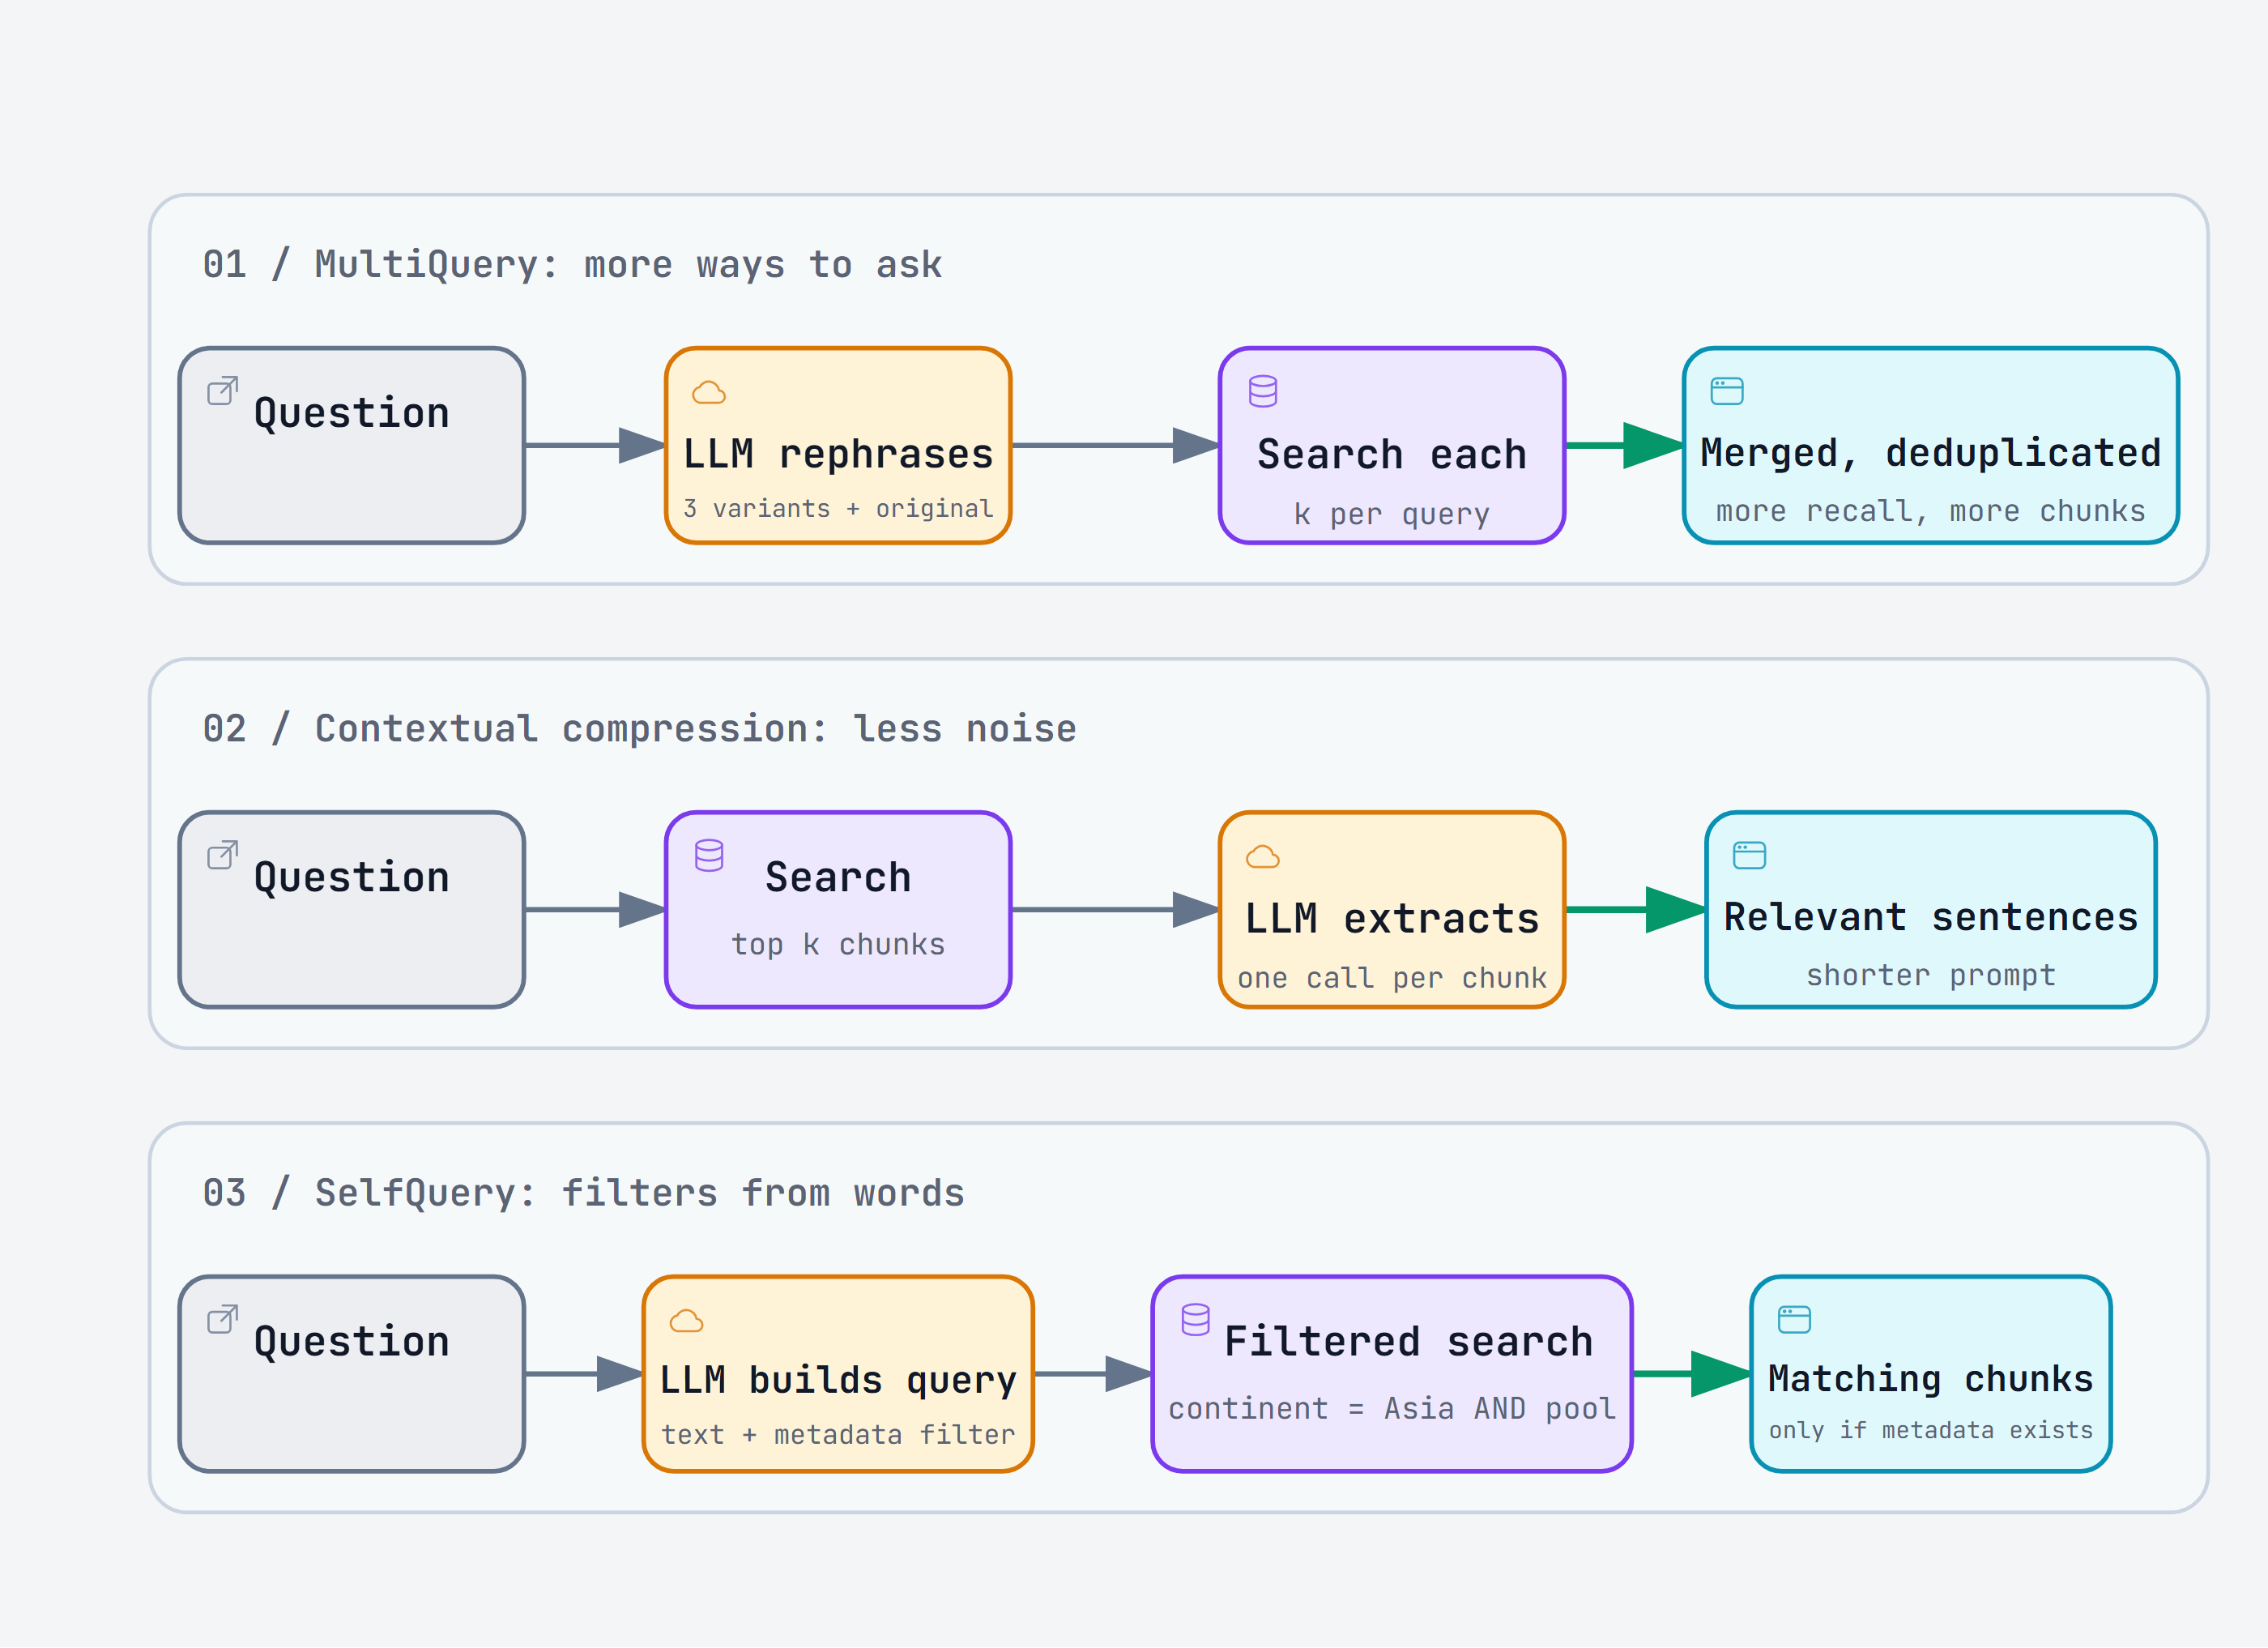

[Open interactive version](../diagrams/advanced_retrievers.html)

In [4]:
from raglab.display import show_diagram

show_diagram("advanced_retrievers")

## 1. MultiQuery: more ways to ask

A question's wording might not match the document's wording. MultiQuery asks the LLM for a few
alternative phrasings, searches with each one (plus the original), and merges the unique results.
Turn on its logger to see the generated queries:

In [5]:
import logging
import sys

from raglab import retrievers

handler = logging.StreamHandler(sys.stdout)
for name in ("langchain_classic.retrievers.multi_query", "langchain_classic.retrievers.self_query.base"):
    log = logging.getLogger(name)
    log.setLevel(logging.INFO)
    log.addHandler(handler)

multiquery = retrievers.get_retriever("multiquery", store, k=4)
docs = multiquery.invoke("Which hotel is best for a relaxing holiday?")
print(f"\n{len(docs)} unique chunks from", sorted({d.metadata.get('hotel_name', '-') for d in docs}))

Generated queries: ['What are the best hotels for a peaceful, restful vacation?', 'Which hotel offers the most relaxing atmosphere and amenities for a holiday?', 'Can you recommend a hotel ideal for unwinding and escaping everyday stress?']



7 unique chunks from ['-', 'Token Lisbon', 'Token Marrakech', 'Token Queenstown']


Note the result size: up to 4 chunks *per query*, so usually more than 4 in total. More chunks
mean more chances to include the evidence, and also a longer, more expensive prompt. Keep that in
mind when comparing scores.

## 2. Contextual compression: less noise

Retrieved chunks contain a lot of text that has nothing to do with the question. A
**compressor** asks the LLM to extract only the relevant parts of each chunk (and drop chunks
with nothing relevant).

In [6]:
question = "What time is check-in at Token Vancouver?"
plain = store.as_retriever(search_kwargs={"k": 4}).invoke(question)
compression = retrievers.get_retriever("compression", store, k=4)
compressed = compression.invoke(question)
print("plain:     ", [len(d.page_content) for d in plain], "characters")
print("compressed:", [len(d.page_content) for d in compressed], "characters")
for d in compressed:
    print("  →", d.page_content[:200].replace("\n", " "))

plain:      [770, 132, 131, 128] characters
compressed: [46] characters
  → Check-in at Token Vancouver starts at 3:30 PM.


Shorter context means a cheaper, more focused generation step. The price is one LLM call per
retrieved chunk *during retrieval*, plus the risk that the extractor drops something the answer needed.

## 3. SelfQuery: let the LLM write the filter

In notebook 03 we wrote metadata filters by hand. SelfQuery gives the LLM a description of the
metadata fields (`retrievers.SELF_QUERY_FIELDS()`) and asks it to translate the question into a
search string **and** a filter.

In [7]:
for field in retrievers.SELF_QUERY_FIELDS()[:4]:
    print(f"{field.name:<16}{field.type:<9}{field.description[:90]}")

hotel_name      string   The hotel the chunk is about. One of: 'Token Lisbon', 'Token Kyoto', 'Token Vancouver', 'T
city            string   City of the hotel. One of: 'Lisbon', 'Kyoto', 'Vancouver', 'Queenstown', 'Marrakech', 'Sin
continent       string   Continent of the hotel. One of: 'Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'S
star_rating     integer  Hotel star rating, 3 to 5


In [8]:
selfquery = retrievers.get_retriever("selfquery", store, k=4)
for q in ["Which Token hotels in Asia have a swimming pool?", "Cheap hotels under $250 a night with a pool"]:
    structured = selfquery.query_constructor.invoke({"query": q})
    print(f"Q: {q}\n   search text: {structured.query!r}\n   filter: {structured.filter}")
    print("   results:", [(d.metadata.get("hotel_name"), d.metadata["source_file"]) for d in selfquery.invoke(q)], "\n")

Q: Which Token hotels in Asia have a swimming pool?
   search text: ' '
   filter: operator=<Operator.AND: 'and'> arguments=[Comparison(comparator=<Comparator.EQ: 'eq'>, attribute='continent', value='Asia'), Comparison(comparator=<Comparator.EQ: 'eq'>, attribute='has_pool', value='true')]


   results: [('Token Singapore', 'guest_reviews.md'), ('Token Singapore', 'dining_guide.md'), ('Token Singapore', 'room_rates.csv'), ('Token Singapore', 'room_rates.csv')] 



Q: Cheap hotels under $250 a night with a pool
   search text: ' '
   filter: operator=<Operator.AND: 'and'> arguments=[Comparison(comparator=<Comparator.LT: 'lt'>, attribute='price_per_night', value=250), Comparison(comparator=<Comparator.EQ: 'eq'>, attribute='has_pool', value='true')]


   results: [('Token Lisbon', 'room_rates.csv'), ('Token Lisbon', 'room_rates.csv'), ('Token Lisbon', 'room_rates.csv'), ('Token Lisbon', 'dining_guide.md')] 



Two things to notice:

- The filter only works on chunks that *have* the metadata. A PDF chunk that `enrich_metadata`
  couldn't pin to a single hotel has no `continent`, so the filter silently excludes it (notebook 03).
- Models sometimes write filter values as strings (`'250'`, `'true'`). `raglab` coerces them to
  the right type before Chroma sees them (`retrievers._typed_translator`); without that, Chroma
  raises an error. Expect this kind of glue code whenever an LLM writes structured queries.

In [9]:
# Quiet the loggers again before scoring 35 questions.
for name in ("langchain_classic.retrievers.multi_query", "langchain_classic.retrievers.self_query.base"):
    logging.getLogger(name).removeHandler(handler)

## 4. Score them all

Now the real test: the same 35 questions as the baseline. Retrieval metrics need no answer
generation, but three of these retrievers make LLM calls *while retrieving*, so this cell costs a
little. As before, the notebook shows the saved full-run results when they exist.

In [10]:
import pandas as pd

from raglab import evaluation as ev
from raglab import llm

items = ev.load_eval("full")
modes = ["similarity", "multiquery", "compression", "selfquery"]
meta = {"profile": "nb04_baseline", "k": 4}

retrieval = {}
for mode in modes:
    name = "nb05_baseline_retrieval" if mode == "similarity" else f"nb06_{mode}_retrieval"
    before = cost.total()
    retrieval[mode] = ev.run_or_load(
        name, lambda m=mode: ev.retrieval_metrics(retrievers.get_retriever(m, store, k=4), items), meta={**meta, "retriever": mode}
    )
    print(f"  {mode}: ${cost.total() - before:.4f} in this run")

ev.compare(retrieval)[["evidence_recall", "hit", "rr", "n_docs", "latency_ms"]]

  similarity: $0.0000 in this run


  multiquery: $0.0010 in this run


  compression: $0.0030 in this run


  selfquery: $0.0041 in this run


,evidence_recall,hit,rr,n_docs,latency_ms
similarity,0.806,0.667,0.736,4.000,1.567
multiquery,0.822,0.700,0.680,5.700,3033.233
compression,0.661,0.500,0.719,2.067,3038.767
selfquery,0.483,0.467,0.461,3.900,1052.667


And by category, where the differences live:

In [11]:
hit_by_category = pd.DataFrame({m: df.groupby("category")["hit"].mean() for m, df in retrieval.items()}).round(2)
hit_by_category

,similarity,multiquery,compression,selfquery
category,,,,
comparative,0.20,0.40,0.00,0.20
conflicting_versions,1.00,1.00,1.00,0.75
factual,0.90,0.90,0.70,0.70
metadata_filter,0.40,0.40,0.40,0.00
multi_hop,0.67,0.67,0.33,0.50


## 5. Does better retrieval give better answers?

Retrieval metrics are a proxy. What we ultimately care about is correct answers. The quick subset
runs live; the full-run table shows all 35 questions.

In [12]:
from raglab import chains

settings = get_settings()
answer_items = items if settings.full_run else ev.load_eval("quick")
answers = {}
for mode in modes:
    name = "nb05_baseline_answers" if mode == "similarity" else f"nb06_{mode}_answers"
    chain = chains.build_rag_chain_with_sources(retrievers.get_retriever(mode, store, k=4))
    answers[mode] = ev.run_or_load(
        name, lambda c=chain: ev.score_answers(ev.run_rag(c, answer_items)), meta={**meta, "retriever": mode}
    )

pd.DataFrame({m: {"accuracy": df["correct"].mean(), "questions": len(df)} for m, df in answers.items()}).T.round(2)

,accuracy,questions
similarity,0.8,5.0
multiquery,0.8,5.0
compression,0.6,5.0
selfquery,0.8,5.0


## 6. What the numbers say

In the run saved here none of the three is a clear win on this corpus, and that is the lesson:

- **MultiQuery** nudged evidence recall up, but it also retrieved about 6 chunks per question
  instead of 4, cost one LLM call per question and added seconds of latency. Part of the gain may
  come simply from *more chunks* (check with `k=8` in the exercises). When we logged the generated
  queries for all 35 questions, the rewriter sometimes read "Token" as crypto *tokens* ("hotels
  that use tokens"). Query rewriting needs domain context.
- **Compression** lowered evidence recall. It can only *remove* text from what the base retriever
  found, and on multi-hop questions it removed exactly the sentences linking two facts. Its benefit
  is shorter prompts; its risk is dropping what the answer needed.
- **SelfQuery** scored *worst*, especially on the metadata-filter questions it was meant to help.
  Two reasons, both visible in section 3: the evidence for those questions sits in PDF profile
  chunks that span two hotels and so carry **no** hotel metadata (the filter excludes them), and
  the generated search text is often empty (`' '`), so results within the filter come back in
  arbitrary order: rate rows instead of profiles.

The fix for SelfQuery isn't a better retriever, it's **better metadata**: chunk the PDF so every
chunk belongs to exactly one hotel. Retrieval techniques can't recover information the index
doesn't carry. Notebook 07 tries a different angle (keyword search plus reranking), and notebook 08
shows how chunking changes these numbers.

## Your turn

1. Score plain similarity with `k=8` (`retrievers.get_retriever("similarity", store, k=8)`).
   Does it match MultiQuery's evidence recall? What does that tell you about where MultiQuery's gain came from?
2. Find a question where SelfQuery's filter is wrong. Use `selfquery.query_constructor.invoke(...)`
   to look at the filter. How would you improve the field descriptions?
3. Build a chain with the compression retriever and compare the prompt token count (`cost.report()`)
   with the baseline chain on the same five questions.

## Key takeaways

- Each advanced retriever spends LLM calls to fix a specific weakness: wording (MultiQuery),
  noise (compression), structure (SelfQuery).
- Measure them on the same evaluation set, per category. Averages hide where each one helps or hurts.
- Check what you're really comparing: number of chunks, cost and latency differ between retrievers.

**Added to raglab:** `retrievers.get_retriever` (modes `similarity`, `mmr`, `multiquery`,
`compression`, `selfquery`), `retrievers.SELF_QUERY_FIELDS`, `retrievers.DOCUMENT_DESCRIPTION`.

In [13]:
cost.report()

model                       calls   in tokens  out tokens       USD
gpt-6-luna                    253      84,826       5,406    0.0112
text-embedding-3-small        108       1,423           0    0.0000
total                         361                            0.0112
